# Experiment 9 — Decision Trees and Random Forest (House Price Dataset)

**Covers:** Full decision tree, restricted decision tree, tree plot, Random Forest, OOB score, evaluation, confusion matrices, ROC curves, feature importance, permutation importance, effect of tree count and CSV export.

**Dataset:** **House Price – California Housing** – `housing.csv` from Kaggle ([camnugent/california-housing-prices](https://www.kaggle.com/datasets/camnugent/california-housing-prices)), 20,640 districts, target `median_house_value`, plus income, house age, rooms, population, location and `ocean_proximity`.

**Data file:** keep `housing.csv` in the **same folder as this notebook** (or replace the file name with its full path, e.g. `pd.read_csv(r"C:\Users\Lab\Desktop\housing.csv")`).

**Remember:** Split → Three models → Metrics → ROC → Tree plot → OOB → Feature importance → Tree count → Compare.

**Binary target:** house value is a number, so it is turned into two balanced classes (above / below the median value).

## Import libraries and load the data

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_validate
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             classification_report, roc_curve)

df = pd.read_csv("housing.csv")

## 1. Same data as Experiment 8

In [2]:
# Binary target: 1 = Expensive (house value above the median), 0 = Not expensive
cols = ["median_income", "housing_median_age", "total_rooms", "total_bedrooms",
        "population", "households", "latitude", "longitude"]
data = df.dropna()

X = data[cols]
y = (data["median_house_value"] > data["median_house_value"].median()).astype(int)

print("Class mapping: 0 = Not expensive, 1 = Expensive")
print(y.value_counts())

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Train:", len(X_train), "Test:", len(X_test))

Class mapping: 0 = Not expensive, 1 = Expensive
median_house_value
0    10217
1    10216
Name: count, dtype: int64
Train: 16346 Test: 4087


## 2. Models (full tree, small tree, random forest)


 Full Tree
              precision    recall  f1-score   support

           0       0.85      0.85      0.85      2044
           1       0.85      0.85      0.85      2043

    accuracy                           0.85      4087
   macro avg       0.85      0.85      0.85      4087
weighted avg       0.85      0.85      0.85      4087



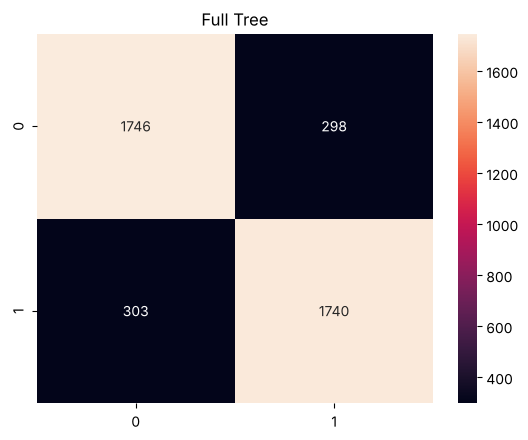


 Small Tree
              precision    recall  f1-score   support

           0       0.82      0.73      0.77      2044
           1       0.76      0.84      0.80      2043

    accuracy                           0.79      4087
   macro avg       0.79      0.79      0.79      4087
weighted avg       0.79      0.79      0.79      4087



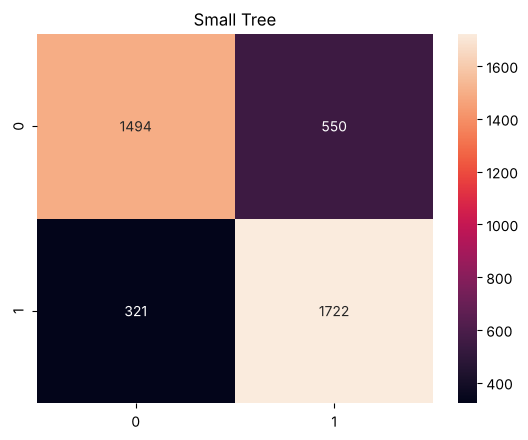


 Random Forest
              precision    recall  f1-score   support

           0       0.88      0.89      0.89      2044
           1       0.89      0.88      0.88      2043

    accuracy                           0.88      4087
   macro avg       0.88      0.88      0.88      4087
weighted avg       0.88      0.88      0.88      4087



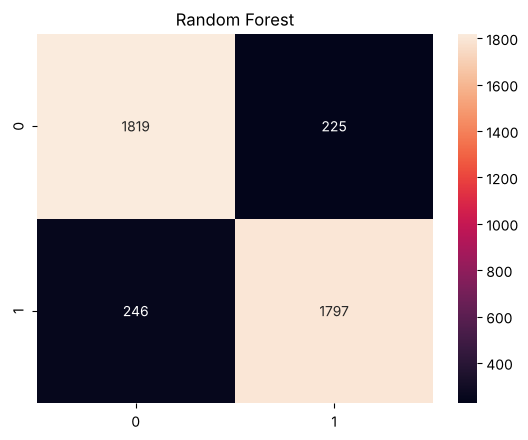

In [3]:
models = {
    "Full Tree": DecisionTreeClassifier(random_state=42),
    "Small Tree": DecisionTreeClassifier(
        max_depth=5, min_samples_split=10,
        min_samples_leaf=5, random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100, oob_score=True, random_state=42, n_jobs=-1
    )
}

results = []
roc = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)[:, 1]

    results.append([
        name,
        accuracy_score(y_train, model.predict(X_train)),
        accuracy_score(y_test, pred),
        precision_score(y_test, pred),
        recall_score(y_test, pred),
        f1_score(y_test, pred),
        roc_auc_score(y_test, prob)
    ])

    print("\n", name)
    print(classification_report(y_test, pred))

    sns.heatmap(confusion_matrix(y_test, pred), annot=True, fmt="d")
    plt.title(name)
    plt.show()

    fpr, tpr, _ = roc_curve(y_test, prob)
    roc[name] = (fpr, tpr)

## 3. ROC curves

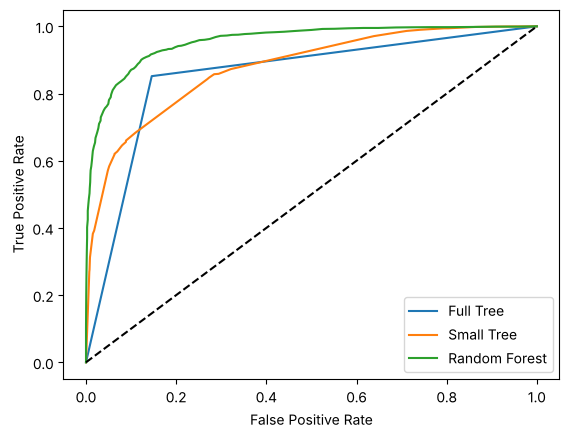

In [4]:
for name, (fpr, tpr) in roc.items():
    plt.plot(fpr, tpr, label=name)
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.show()

## 4. Tree details and plot

Full Tree Depth: 25 Leaves: 1635
Small Tree Depth: 5 Leaves: 32


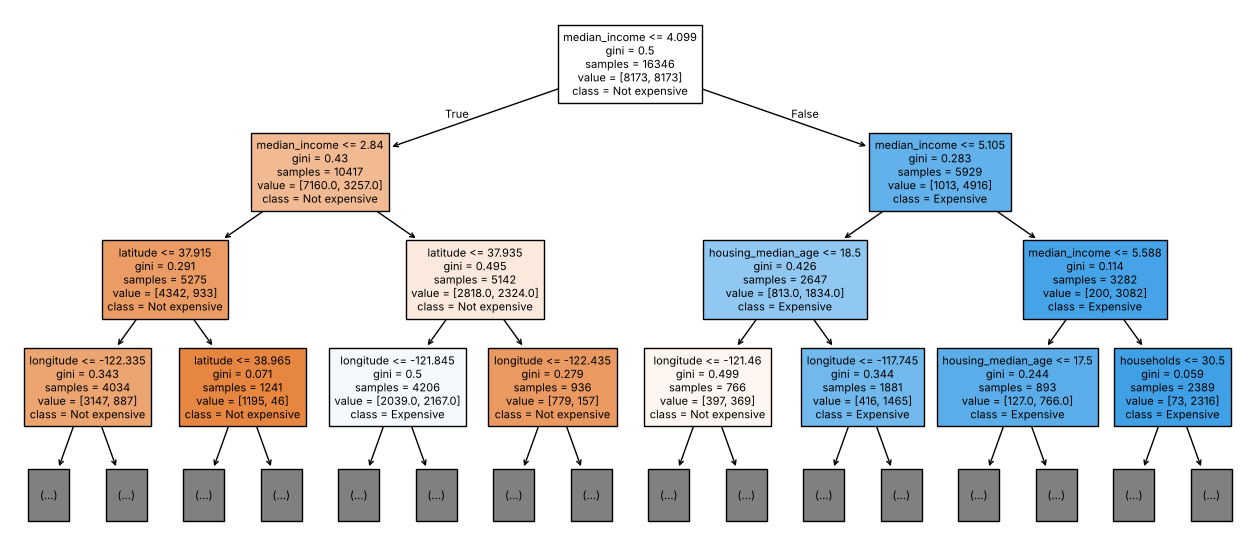

In [5]:
for name in ["Full Tree", "Small Tree"]:
    tree = models[name]
    print(name, "Depth:", tree.get_depth(), "Leaves:", tree.get_n_leaves())

plt.figure(figsize=(16, 7))
plot_tree(models["Small Tree"], feature_names=cols,
          class_names=["Not expensive", "Expensive"],
          max_depth=3, filled=True, fontsize=8)
plt.show()

## 5. Random Forest OOB score
Out-of-bag score = accuracy on the training rows each tree did not see.

In [6]:
rf = models["Random Forest"]
print("OOB Score:", rf.oob_score_)

OOB Score: 0.8816224152697908


## 6. Feature importance

                        Tree    Forest  Permutation  Permutation SD
median_income       0.367157  0.307204     0.173403        0.003420
housing_median_age  0.049856  0.062254     0.009249        0.001508
total_rooms         0.051167  0.079085     0.013286        0.003151
total_bedrooms      0.041598  0.062594     0.001346        0.001277
population          0.067070  0.087048     0.051676        0.003148
households          0.031122  0.063427     0.013286        0.002862
latitude            0.180638  0.168043     0.184463        0.003700
longitude           0.211392  0.170345     0.175703        0.005329


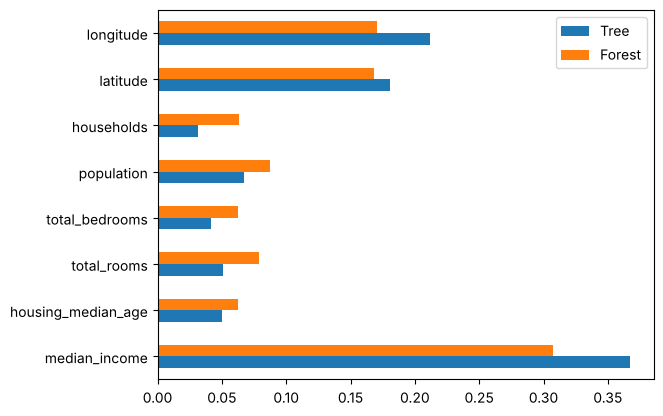

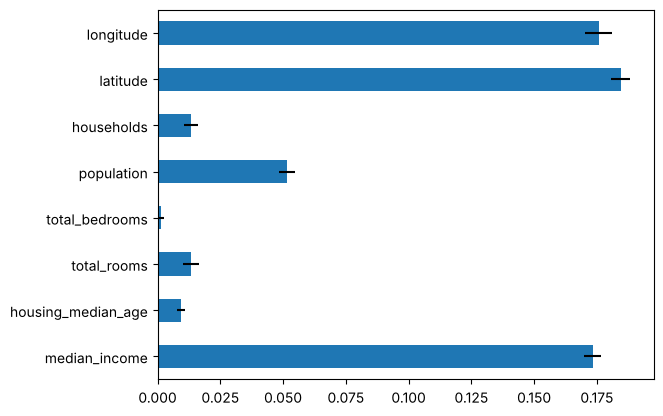

In [7]:
perm = permutation_importance(
    rf, X_test, y_test, n_repeats=10, random_state=42
)

importance = pd.DataFrame({
    "Tree": models["Full Tree"].feature_importances_,
    "Forest": rf.feature_importances_,
    "Permutation": perm.importances_mean,
    "Permutation SD": perm.importances_std
}, index=cols)

print(importance)

importance[["Tree", "Forest"]].plot(kind="barh")
plt.show()

importance["Permutation"].plot(
    kind="barh", xerr=importance["Permutation SD"]
)
plt.show()

## 7. Effect of number of trees (5-fold CV)

   Trees  Accuracy        F1       AUC
0     10  0.870366  0.866251  0.941189
1     25  0.879114  0.878084  0.951063
2     50  0.879848  0.878150  0.954600
3    100  0.882479  0.881205  0.955698
4    200  0.885170  0.884068  0.956478


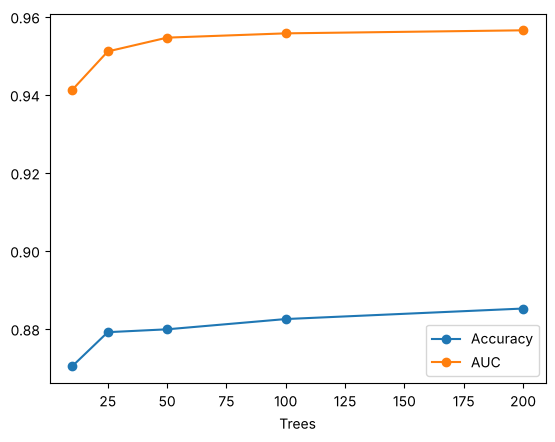

In [8]:
rows = []
for n in [10, 25, 50, 100, 200]:
    model = RandomForestClassifier(n_estimators=n, random_state=42, n_jobs=-1)
    cv = cross_validate(model, X_train, y_train, cv=5,
                        scoring=["accuracy", "f1", "roc_auc"])
    rows.append([n, cv["test_accuracy"].mean(),
                 cv["test_f1"].mean(), cv["test_roc_auc"].mean()])

tree_results = pd.DataFrame(
    rows, columns=["Trees", "Accuracy", "F1", "AUC"]
)
print(tree_results)

tree_results.plot(x="Trees", y=["Accuracy", "AUC"], marker="o")
plt.show()

## 8. Comparison and save

               Train Accuracy  Accuracy  Precision    Recall        F1  \
Model                                                                    
Full Tree            1.000000  0.852948   0.853778  0.851689  0.852732   
Small Tree           0.792243  0.786885   0.757923  0.842878  0.798146   
Random Forest        1.000000  0.884757   0.888724  0.879589  0.884133   

                    AUC  
Model                    
Full Tree      0.852948  
Small Tree     0.876225  
Random Forest  0.955247  


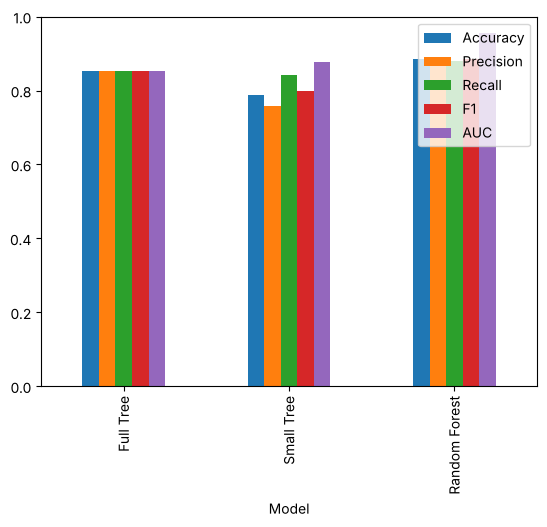

Saved tree_results.csv, feature_importance.csv, tree_count.csv


In [9]:
result = pd.DataFrame(results, columns=[
    "Model", "Train Accuracy", "Accuracy",
    "Precision", "Recall", "F1", "AUC"
]).set_index("Model")

print(result)
result.drop(columns="Train Accuracy").plot(kind="bar", ylim=(0, 1))
plt.show()

result.to_csv("tree_results.csv")
importance.to_csv("feature_importance.csv")
tree_results.to_csv("tree_count.csv", index=False)
print("Saved tree_results.csv, feature_importance.csv, tree_count.csv")

## Result / Conclusion
- The full tree (depth 25, 1,635 leaves) has train accuracy 1.00 but test accuracy 0.853 (AUC 0.853) – over-fitting.
- The small tree (depth 5, 32 leaves) is simpler but less accurate (0.787, AUC 0.876).
- The **Random Forest is clearly best:** test accuracy 0.885, F1 0.884, AUC 0.955, OOB score 0.882.
- Feature importance: `median_income`, `latitude` and `longitude` dominate (permutation importance 0.17–0.18 each) – income and location decide house price. CV AUC improves from 0.941 (10 trees) to 0.956 (200 trees).